# 03 · Modelagem
Fase 4 do CRISP-DM. Dois modelos:
1. **K-Means** sobre o perfil de cada jogador → estilos de jogador (o mesmo que a página Minha Coleção mostra);
2. **Regra de veto do CLIP** (`src/jogo.veto_clip`) → quando o segundo juiz derruba a foto aceita pela IA.

> **Dados:** enquanto a turma não joga, os notebooks usam `data/processed/capturas_demo.csv` (fictício, gerado por `python -m src.exemplo`). Para usar os dados reais, baixe o CSV na página **Avaliação** do app e salve como `data/processed/avaliacao_juizes.csv`: os notebooks passam a ler esse arquivo sozinhos. As conclusões abaixo só valem de verdade com os dados reais.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.clustering import agrupar, escolher_k
from src.jogo import NOMES_ESTILO, RAZAO_TELA, VETO_RANK, normalizar_juiz
from src.perfil import similaridade_cosseno
from src.temas import TEMAS

sns.set_theme(style="whitegrid")
NOME_TEMA = {t.id: t.nome for t in TEMAS} | {"nenhum": "nenhum"}
perfis = pd.read_csv(RAIZ / "data/processed/perfis_jogadores.csv", index_col="usuario")
capturas = pd.read_csv(RAIZ / "data/processed/capturas_limpas.csv", parse_dates=["criado_em"])
perfis.shape, capturas.shape

((9, 5), (198, 35))

## 1. K-Means: estilos de jogador
### Escolha do k
Testamos k de 2 a 6 com o método do cotovelo (inércia) e a silhueta. Ficamos com o k de maior silhueta.

,k,inercia,silhueta
0,2,1.375,0.509
1,3,0.495,0.712
2,4,0.052,0.812
3,5,0.034,0.621
4,6,0.017,0.443


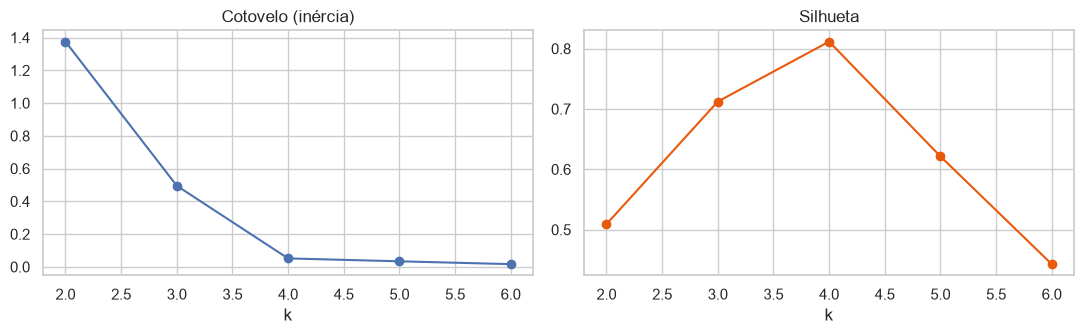

In [2]:
tabela = escolher_k(perfis)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(tabela["k"], tabela["inercia"], marker="o"); ax[0].set_title("Cotovelo (inércia)")
ax[1].plot(tabela["k"], tabela["silhueta"], marker="o", color="#e8590c"); ax[1].set_title("Silhueta")
for a in ax: a.set_xlabel("k")
plt.tight_layout()
tabela.round(3)

In [3]:
rotulos, centros = agrupar(perfis, nomes=NOMES_ESTILO)
k = len(centros)
print("k escolhido:", k)
centros.rename(columns=NOME_TEMA).round(2)

k escolhido: 4


,Carros,Plantas e flores,Pássaros,Cachorros e gatos,Peças e periféricos de computador,perfil
0,0.74,0.00,0.00,0.00,0.26,Caçador de carros
1,0.00,0.24,0.00,0.76,0.00,Amigo dos bichos
2,0.00,0.57,0.43,0.00,0.00,Naturalista + Observador de aves
3,0.31,0.00,0.00,0.00,0.69,Garimpeiro tech


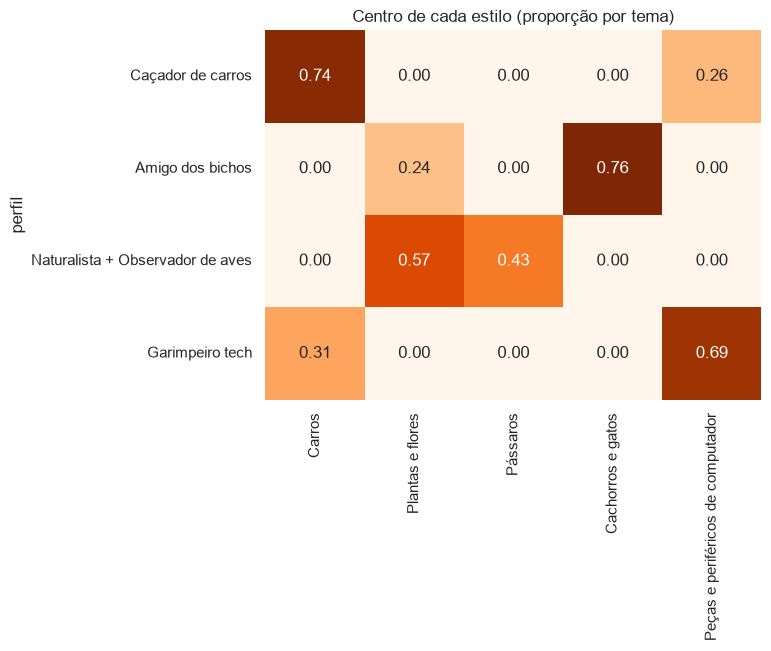

In [4]:
sns.heatmap(centros.set_index("perfil").rename(columns=NOME_TEMA), annot=True, fmt=".2f", cmap="Oranges", cbar=False)
plt.title("Centro de cada estilo (proporção por tema)");

In [5]:
rotulos.groupby("perfil")["usuario"].agg(["count", list])

,count,list
perfil,,
Amigo dos bichos,2,"[u02, u06]"
Caçador de carros,3,"[u04, u07, u08]"
Garimpeiro tech,2,"[u03, u09]"
Naturalista + Observador de aves,2,"[u01, u05]"


### Similaridade do cosseno entre jogadores
Quem joga parecido? Útil para sugerir "jogadores com o seu estilo" no pódio.

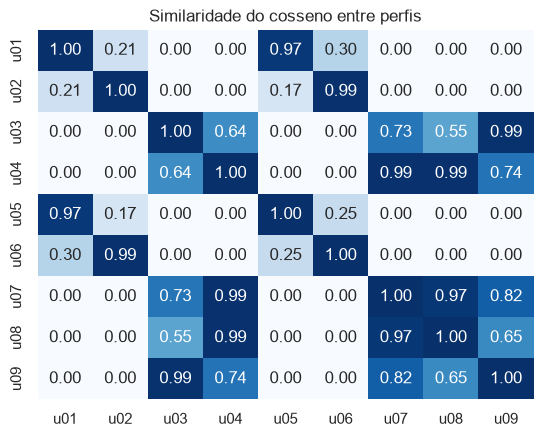

In [6]:
usuarios = list(perfis.index)
sim = pd.DataFrame([[similaridade_cosseno(perfis.loc[a], perfis.loc[b]) for b in usuarios] for a in usuarios], index=usuarios, columns=usuarios)
sns.heatmap(sim, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False)
plt.title("Similaridade do cosseno entre perfis");

## 2. Regra de veto do CLIP
O CLIP compara a foto com frases de 7 grupos (5 temas, "tela" e "nenhum"). Com os dois juízes, ele derruba a foto aceita pela IA quando:
- o tema da IA fica **fora dos `VETO_RANK` primeiros** palpites do CLIP; ou
- "tela" tem pelo menos **`RAZAO_TELA` vezes** a chance do tema (não vale para peças: monitor ligado é peça).

Abaixo, como as probabilidades do CLIP se distribuem nas fotos que a IA achou reais × de tela.

VETO_RANK = 2 | RAZAO_TELA = 3


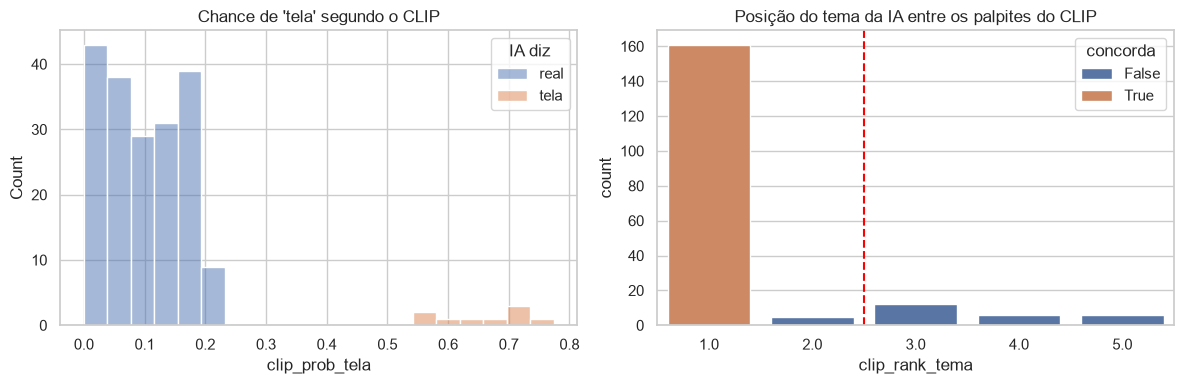

In [7]:
print("VETO_RANK =", VETO_RANK, "| RAZAO_TELA =", RAZAO_TELA)
ambos = capturas[capturas["juiz"].map(normalizar_juiz) == "ia+clip"].copy()
ambos["IA diz"] = ambos["foto_real"].map({True: "real", False: "tela"})
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(ambos, x="clip_prob_tela", hue="IA diz", bins=20, ax=ax[0])
ax[0].set_title("Chance de 'tela' segundo o CLIP")
sns.countplot(ambos, x="clip_rank_tema", hue="concorda", ax=ax[1])
ax[1].axvline(VETO_RANK - 0.5, color="red", ls="--")
ax[1].set_title("Posição do tema da IA entre os palpites do CLIP")
plt.tight_layout()

In [8]:
vetadas = ambos[ambos["recusa"].fillna("").str.contains("CLIP|juízes")]
print(f"O CLIP vetou {len(vetadas)} de {len(ambos)} fotos julgadas pelos dois ({len(vetadas)/max(len(ambos),1):.0%})")
vetadas["recusa"].value_counts()

O CLIP vetou 22 de 198 fotos julgadas pelos dois (11%)


recusa
os juízes discordaram do tema    22
Name: count, dtype: int64